## import libraries

In [29]:
import os
from pathlib import Path
import zipfile
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
import torch.optim as optim

## Reading Data

In [32]:
ZIP_PATH = r"D:\ahmed\Python\AI\Hackathon 9.0\archive.zip"
DATA_ROOT = Path(ZIP_PATH).parent / "NEU-DET"

# Extract the image folders from the ZIP so ImageFolder can read them.
with zipfile.ZipFile(ZIP_PATH) as z:
    image_members = [
        name for name in z.namelist()
        if name.startswith(("NEU-DET/train/images/", "NEU-DET/validation/images/"))
    ]
    z.extractall(Path(ZIP_PATH).parent, image_members)

train = DATA_ROOT / "train"
test = DATA_ROOT / "validation"
train_images = train / "images"
test_images = test / "images"
print(f"Training images: {train_images}")
print(f"Validation images: {test_images}")

Training images: D:\ahmed\Python\AI\Hackathon 9.0\NEU-DET\train\images
Validation images: D:\ahmed\Python\AI\Hackathon 9.0\NEU-DET\validation\images


In [33]:
# Make your random seed ==> use the common settings
def set_seed(seed):
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)

In [34]:
train_data = str(train_images)
test_data = str(test_images)

BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 0.001

transform = transforms.Compose([
        transforms.Grayscale(num_output_channels=1),
        transforms.Resize((200, 200)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5], std=[0.5])
    ])

dataset = datasets.ImageFolder(
    root=train_data,
    transform=transform
)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

test_dataset = datasets.ImageFolder(
    root=test_data,
    transform=transform
)

loader_generator = torch.Generator().manual_seed(42)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=loader_generator)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"class names: {dataset.classes}")
print(f"dataset split: train={len(train_dataset)}, val={len(val_dataset)}, test={len(test_dataset)}")

class names: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
dataset split: train=1152, val=288, test=360


## CNN Architecture

In [30]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding='same'),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 25 * 25, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 6)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x    

## Making Model & Optimizer


In [31]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = CNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr = LEARNING_RATE
)

print(model)
print("Device:", device)

CNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=40000, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=6, bias=True)
  )
)
Device: cpu


In [10]:
total = 0
for name, p in model.named_parameters():
    print(name, "->", tuple(p.shape), " =", p.numel(), "numbers")
    total += p.numel()

print("\nTotal parameters:", total)

features.0.weight -> (16, 1, 3, 3)  = 144 numbers
features.0.bias -> (16,)  = 16 numbers
features.3.weight -> (32, 16, 3, 3)  = 4608 numbers
features.3.bias -> (32,)  = 32 numbers
features.6.weight -> (64, 32, 3, 3)  = 18432 numbers
features.6.bias -> (64,)  = 64 numbers
classifier.1.weight -> (128, 40000)  = 5120000 numbers
classifier.1.bias -> (128,)  = 128 numbers
classifier.4.weight -> (6, 128)  = 768 numbers
classifier.4.bias -> (6,)  = 6 numbers

Total parameters: 5144198


## Train model

In [35]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    history = {
        'train_loss': [],
        'val_loss': [],
        'train_accuracy': [],
        'val_accuracy': []
    }

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct_predictions = 0
        total_predictions = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_predictions += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_predictions

        # Validation phase
        model.eval()
        val_running_loss = 0.0
        val_correct_predictions = 0
        val_total_predictions = 0

        with torch.no_grad():
            for val_images, val_labels in val_loader:
                val_images, val_labels = val_images.to(device), val_labels.to(device)
                val_outputs = model(val_images)
                val_loss = criterion(val_outputs, val_labels)

                val_running_loss += val_loss.item() * val_images.size(0)
                _, val_predicted = torch.max(val_outputs.data, 1)
                val_total_predictions += val_labels.size(0)
                val_correct_predictions += (val_predicted == val_labels).sum().item()

        val_epoch_loss = val_running_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_predictions

        print(f"Epoch [{epoch+1}/{num_epochs}], "
              f"Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.4f}, "
              f"Val Loss: {val_epoch_loss:.4f}, Val Accuracy: {val_epoch_accuracy:.4f}")
        history['train_loss'].append(epoch_loss)
        history['val_loss'].append(val_epoch_loss)
        history['train_accuracy'].append(epoch_accuracy)
        history['val_accuracy'].append(val_epoch_accuracy)


    return history



## Training

In [36]:
# Start training; the function prints train/validation metrics after each epoch.
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    num_epochs=EPOCHS
)

Epoch [1/20], Train Loss: 1.3229, Train Accuracy: 0.4948, Val Loss: 0.9638, Val Accuracy: 0.6458
Epoch [2/20], Train Loss: 0.8195, Train Accuracy: 0.6936, Val Loss: 0.7162, Val Accuracy: 0.7847
Epoch [3/20], Train Loss: 0.5157, Train Accuracy: 0.8186, Val Loss: 0.4061, Val Accuracy: 0.8646
Epoch [4/20], Train Loss: 0.4794, Train Accuracy: 0.8281, Val Loss: 0.6890, Val Accuracy: 0.7049
Epoch [5/20], Train Loss: 0.3892, Train Accuracy: 0.8698, Val Loss: 0.2248, Val Accuracy: 0.9444
Epoch [6/20], Train Loss: 0.2973, Train Accuracy: 0.8924, Val Loss: 0.2312, Val Accuracy: 0.9410
Epoch [7/20], Train Loss: 0.2598, Train Accuracy: 0.9097, Val Loss: 0.2193, Val Accuracy: 0.9340
Epoch [8/20], Train Loss: 0.2158, Train Accuracy: 0.9245, Val Loss: 0.1713, Val Accuracy: 0.9444
Epoch [9/20], Train Loss: 0.2166, Train Accuracy: 0.9271, Val Loss: 0.1633, Val Accuracy: 0.9549
Epoch [10/20], Train Loss: 0.1971, Train Accuracy: 0.9384, Val Loss: 0.1844, Val Accuracy: 0.9444
Epoch [11/20], Train Loss: 0.

## plot the model

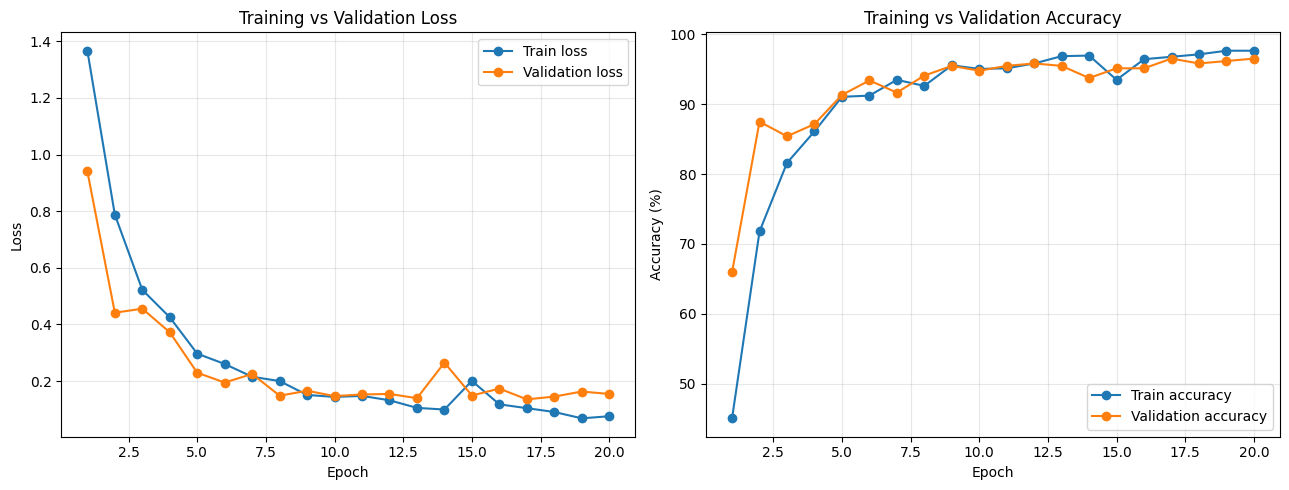

In [14]:
epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Loss plot
axes[0].plot(epochs, history["train_loss"], marker="o", label="Train loss")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy plot (convert fractions to percentages)
axes[1].plot(epochs, [acc * 100 for acc in history["train_accuracy"]], marker="o", label="Train accuracy")
axes[1].plot(epochs, [acc * 100 for acc in history["val_accuracy"]], marker="o", label="Validation accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## comparsion

Epoch [1/10], Train Loss: 1.2645, Train Accuracy: 0.5278, Val Loss: 0.8090, Val Accuracy: 0.7431
Epoch [2/10], Train Loss: 0.6702, Train Accuracy: 0.7700, Val Loss: 0.4979, Val Accuracy: 0.8507
Epoch [3/10], Train Loss: 0.5218, Train Accuracy: 0.8212, Val Loss: 0.4170, Val Accuracy: 0.8958
Epoch [4/10], Train Loss: 0.5016, Train Accuracy: 0.8411, Val Loss: 0.3054, Val Accuracy: 0.9132
Epoch [5/10], Train Loss: 0.3065, Train Accuracy: 0.8950, Val Loss: 0.2666, Val Accuracy: 0.9062
Epoch [6/10], Train Loss: 0.2354, Train Accuracy: 0.9210, Val Loss: 0.1712, Val Accuracy: 0.9444
Epoch [7/10], Train Loss: 0.2780, Train Accuracy: 0.9062, Val Loss: 0.2534, Val Accuracy: 0.9028
Epoch [8/10], Train Loss: 0.2149, Train Accuracy: 0.9314, Val Loss: 0.1699, Val Accuracy: 0.9236
Epoch [9/10], Train Loss: 0.1691, Train Accuracy: 0.9505, Val Loss: 0.1915, Val Accuracy: 0.9514
Epoch [10/10], Train Loss: 0.1499, Train Accuracy: 0.9531, Val Loss: 0.1373, Val Accuracy: 0.9479
Epoch [1/10], Train Loss: 2.2

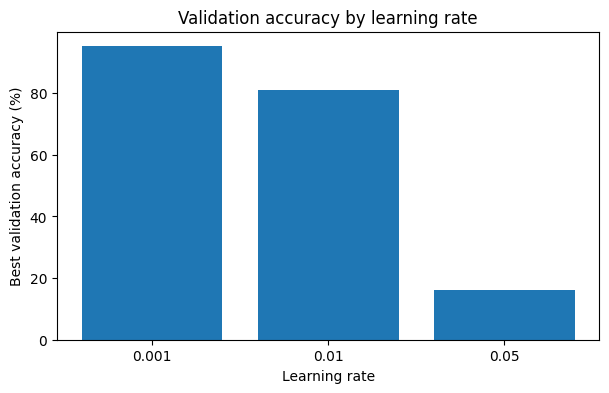

In [ ]:
# Compare validation accuracy using the same model/optimizer type and data split.
learning_rates = [0.001, 0.01, 0.05]
COMPARE_EPOCHS = 10  # Increase to EPOCHS for a longer comparison.
results = []

for lr in learning_rates:
    set_seed(42)  # Give each run the same starting weights.
    train_loader.generator.manual_seed(42)  # Keep the shuffled batch order comparable.

    trial_model = CNN().to(device)
    trial_optimizer = optim.Adam(trial_model.parameters(), lr=lr)

    trial_history = train_model(
        model=trial_model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        optimizer=trial_optimizer,
        num_epochs=COMPARE_EPOCHS
    )

    best_val_acc = max(trial_history["val_accuracy"])
    results.append({"learning_rate": lr, "best_val_accuracy": best_val_acc})

results_df = pd.DataFrame(results)
print(results_df)

plt.figure(figsize=(7, 4))
plt.bar(results_df["learning_rate"].astype(str), results_df["best_val_accuracy"] * 100)
plt.xlabel("Learning rate")
plt.ylabel("Best validation accuracy (%)")
plt.title("Validation accuracy by learning rate")
plt.show()


Epoch [1/10], Train Loss: 1.2645, Train Accuracy: 0.5278, Val Loss: 0.8090, Val Accuracy: 0.7431
Epoch [2/10], Train Loss: 0.6702, Train Accuracy: 0.7700, Val Loss: 0.4979, Val Accuracy: 0.8507
Epoch [3/10], Train Loss: 0.5218, Train Accuracy: 0.8212, Val Loss: 0.4170, Val Accuracy: 0.8958
Epoch [4/10], Train Loss: 0.5016, Train Accuracy: 0.8411, Val Loss: 0.3054, Val Accuracy: 0.9132
Epoch [5/10], Train Loss: 0.3065, Train Accuracy: 0.8950, Val Loss: 0.2666, Val Accuracy: 0.9062
Epoch [6/10], Train Loss: 0.2354, Train Accuracy: 0.9210, Val Loss: 0.1712, Val Accuracy: 0.9444
Epoch [7/10], Train Loss: 0.2780, Train Accuracy: 0.9062, Val Loss: 0.2534, Val Accuracy: 0.9028
Epoch [8/10], Train Loss: 0.2149, Train Accuracy: 0.9314, Val Loss: 0.1699, Val Accuracy: 0.9236
Epoch [9/10], Train Loss: 0.1691, Train Accuracy: 0.9505, Val Loss: 0.1915, Val Accuracy: 0.9514
Epoch [10/10], Train Loss: 0.1499, Train Accuracy: 0.9531, Val Loss: 0.1373, Val Accuracy: 0.9479
Epoch [1/10], Train Loss: 1.7

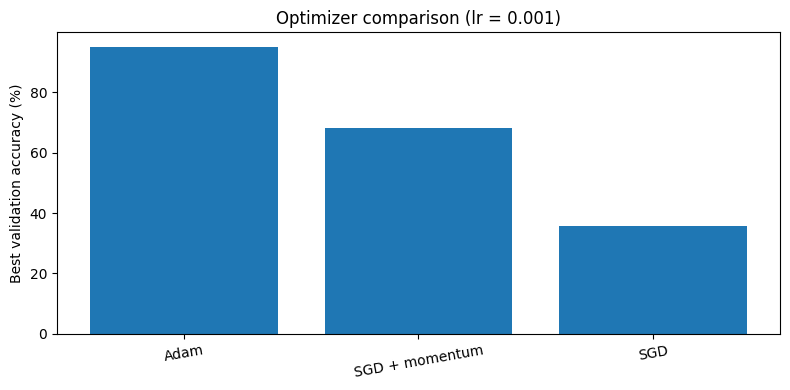

In [25]:
# Compare Adam, SGD with momentum, and plain SGD at the same learning rate.
LR = 0.001
OPTIMIZER_COMPARE_EPOCHS = 10
optimizer_configs = {
    "Adam": lambda params: optim.Adam(params, lr=LR),
    "SGD + momentum": lambda params: optim.SGD(params, lr=LR, momentum=0.9),
    "SGD": lambda params: optim.SGD(params, lr=LR),
}
optimizer_results = []

for optimizer_name, make_optimizer in optimizer_configs.items():
    set_seed(42)  # Same initial weights for a fairer comparison.
    train_loader.generator.manual_seed(42)  # Same shuffled batches for each run.

    trial_model = CNN().to(device)
    trial_optimizer = make_optimizer(trial_model.parameters())
    trial_history = train_model(
        model=trial_model,
        train_loader=train_loader,
        val_loader=val_loader,
        criterion=criterion,
        optimizer=trial_optimizer,
        num_epochs=OPTIMIZER_COMPARE_EPOCHS
    )

    optimizer_results.append({
        "optimizer": optimizer_name,
        "best_val_accuracy": max(trial_history["val_accuracy"]),
        "final_val_accuracy": trial_history["val_accuracy"][-1]
    })

optimizer_results_df = pd.DataFrame(optimizer_results)
print(optimizer_results_df)

plt.figure(figsize=(8, 4))
plt.bar(optimizer_results_df["optimizer"], optimizer_results_df["best_val_accuracy"] * 100)
plt.ylabel("Best validation accuracy (%)")
plt.title(f"Optimizer comparison (lr = {LR})")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()


## Final Validation

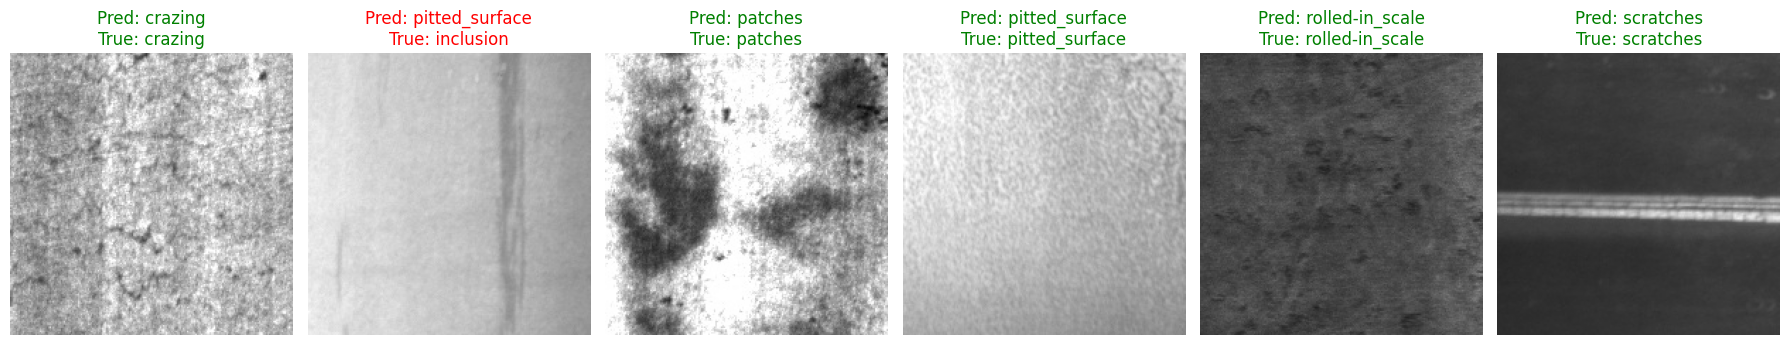

In [27]:
# Display one random test image from each class with its prediction.
import random

class_names = test_dataset.classes
selected_indices = []

for class_id in range(len(class_names)):
    class_indices = [
        idx for idx, label in enumerate(test_dataset.targets)
        if label == class_id
    ]
    if not class_indices:
        print(f"No test images found for class: {class_names[class_id]}")
        continue
    selected_indices.append(random.choice(class_indices))

samples = [test_dataset[idx] for idx in selected_indices]
images = torch.stack([image for image, _ in samples]).to(device)
labels = torch.tensor([label for _, label in samples], device=device)

model.eval()
with torch.no_grad():
    predictions = model(images).argmax(dim=1)

num_images = len(samples)
fig, axes = plt.subplots(1, num_images, figsize=(3 * num_images, 4))
if num_images == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    image = images[i].cpu() * 0.5 + 0.5  # Undo Normalize(mean=0.5, std=0.5).
    predicted_name = class_names[predictions[i].item()]
    actual_name = class_names[labels[i].item()]
    color = "green" if predictions[i] == labels[i] else "red"

    ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Pred: {predicted_name}\nTrue: {actual_name}", color=color)
    ax.axis("off")

plt.tight_layout()
plt.show()


## best accuracy on test data

In [41]:
# Evaluate the trained model once on the held-out test set.
model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)
        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_accuracy = 100 * test_correct / test_total
print(f"Test accuracy: {test_accuracy:.2f}% ({test_correct}/{test_total})")


Test accuracy: 84.72% (305/360)


In [42]:
# Promote the retrained checkpoint saved at the best validation epoch.
# This is a new model; it cannot recover the original model's lost weights.
from pathlib import Path

repo_models = Path.cwd() / "neu-det-cnn" / "models"
source_checkpoint = repo_models / "notebook_sequence_candidate.pth"
best_checkpoint = torch.load(source_checkpoint, map_location="cpu", weights_only=True)
torch.save(best_checkpoint, repo_models / "neu_det_cnn.pth")
print(f"Promoted best-validation checkpoint: {repo_models / 'neu_det_cnn.pth'}")
print(f"Best training holdout accuracy: {best_checkpoint['best_val_accuracy']:.2%}")


Promoted best-validation checkpoint: d:\ahmed\Python\AI\Hackathon 9.0\neu-det-cnn\models\neu_det_cnn.pth
Best training holdout accuracy: 96.53%
